# 주택 가격 예측하기

메인퀘스트에 오신 것을 환영합니다!

이번 퀘스트의 목표는 여러 특성들을 종합적으로 고려하여 가장 주택 가격을 잘 예측하는 회귀모델을 만드는 것입니다.

- 예측할 값(y): SalePrice
- 평가지표: RMSE

예시 형식:
~~~
Id,SalePrice
1461,169000.1
1462,187724.1233
1463,175221
etc.
~~~

### 데이터 확인 및 불러오기

In [110]:
import numpy as np
import pandas as pd
import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

In [111]:
train_df = pd.read_csv('./train.csv')
test_df = pd.read_csv('./test.csv')

In [112]:
# train 데이터셋 정보
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 1168 entries, 0 to 1167
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1168 non-null   int64  
 1   MSSubClass     1168 non-null   int64  
 2   MSZoning       1168 non-null   str    
 3   LotFrontage    950 non-null    float64
 4   LotArea        1168 non-null   int64  
 5   Street         1168 non-null   str    
 6   Alley          70 non-null     str    
 7   LotShape       1168 non-null   str    
 8   LandContour    1168 non-null   str    
 9   Utilities      1168 non-null   str    
 10  LotConfig      1168 non-null   str    
 11  LandSlope      1168 non-null   str    
 12  Neighborhood   1168 non-null   str    
 13  Condition1     1168 non-null   str    
 14  Condition2     1168 non-null   str    
 15  BldgType       1168 non-null   str    
 16  HouseStyle     1168 non-null   str    
 17  OverallQual    1168 non-null   int64  
 18  OverallCond    1168

특성이 너무 많습니다! 어떻게 하면 좋을까요?

참고로 각각의 특성은 다음을 나타냅니다.

| 변수명               | 설명 (한국어)                         |
| ----------------- | -------------------------------- |
| **SalePrice**     | 주택의 판매 가격(달러). 예측해야 하는 타겟 변수     |
| **MSSubClass**    | 건물 등급(건물 종류 분류)                  |
| **MSZoning**      | 토지 용도 구분(일반적인 구역 분류)             |
| **LotFrontage**   | 도로에 접한 토지 길이 (피트 단위)             |
| **LotArea**       | 토지 면적 (평방 피트)                    |
| **Street**        | 도로 접근 방식                         |
| **Alley**         | 골목(후면 도로) 접근 방식                  |
| **LotShape**      | 토지의 전반적인 모양                      |
| **LandContour**   | 토지의 평탄도                          |
| **Utilities**     | 사용 가능한 공공시설(전기, 수도 등)            |
| **LotConfig**     | 토지 배치 형태                         |
| **LandSlope**     | 토지의 경사도                          |
| **Neighborhood**  | Ames 시 내의 물리적 위치(주변 지역)          |
| **Condition1**    | 주요 도로·철도에 대한 근접도                 |
| **Condition2**    | 두 번째 주요 도로·철도에 대한 근접도            |
| **BldgType**      | 주거 건물 유형 (단독, 다세대 등)             |
| **HouseStyle**    | 주택의 건축 양식                        |
| **OverallQual**   | 자재 및 마감 품질 종합 평가                 |
| **OverallCond**   | 주택의 전반적인 상태 평가                   |
| **YearBuilt**     | 최초 건축 연도                         |
| **YearRemodAdd**  | 리모델링/개조 연도                       |
| **RoofStyle**     | 지붕 스타일                           |
| **RoofMatl**      | 지붕 재료                            |
| **Exterior1st**   | 외장 마감재(주 재료)                     |
| **Exterior2nd**   | 외장 마감재(보조 재료, 2번째)               |
| **MasVnrType**    | 석조 베니어 타입                        |
| **MasVnrArea**    | 석조 베니어 면적 (평방 피트)                |
| **ExterQual**     | 외장재 품질 평가                        |
| **ExterCond**     | 외장재 상태 평가                        |
| **Foundation**    | 기초(Foundation) 유형                |
| **BsmtQual**      | 지하실 높이 평가                        |
| **BsmtCond**      | 지하실 상태 평가                        |
| **BsmtExposure**  | 지하실 외부 노출 여부(출입구/창문 등)           |
| **BsmtFinType1**  | 주요 지하실 마감 구역 유형                  |
| **BsmtFinSF1**    | 주요 지하실 마감 면적 (평방 피트)             |
| **BsmtFinType2**  | 보조 지하실 마감 구역 유형                  |
| **BsmtFinSF2**    | 보조 지하실 마감 면적 (평방 피트)             |
| **BsmtUnfSF**     | 미완성 지하실 면적 (평방 피트)               |
| **TotalBsmtSF**   | 지하실 전체 면적 (평방 피트)                |
| **Heating**       | 난방 시스템 종류                        |
| **HeatingQC**     | 난방 품질 및 상태                       |
| **CentralAir**    | 중앙 에어컨 설치 여부                     |
| **Electrical**    | 전기 시스템 종류                        |
| **1stFlrSF**      | 1층 면적 (평방 피트)                    |
| **2ndFlrSF**      | 2층 면적 (평방 피트)                    |
| **LowQualFinSF**  | 저품질 마감 공간 면적 (전체 층 합산)           |
| **GrLivArea**     | 지상(Above grade) 생활 공간 면적 (평방 피트) |
| **BsmtFullBath**  | 지하실 완비 욕실 수                      |
| **BsmtHalfBath**  | 지하실 반 욕실 수                       |
| **FullBath**      | 지상 완비 욕실 수                       |
| **HalfBath**      | 지상 반 욕실 수                        |
| **Bedroom**       | 지하실 제외 침실 수                      |
| **Kitchen**       | 주방 수                             |
| **KitchenQual**   | 주방 품질                            |
| **TotRmsAbvGrd**  | 지상 전체 방 개수 (욕실 제외)               |
| **Functional**    | 주택 기능성 평가                        |
| **Fireplaces**    | 벽난로 개수                           |
| **FireplaceQu**   | 벽난로 품질                           |
| **GarageType**    | 차고 위치(유형)                        |
| **GarageYrBlt**   | 차고 건축 연도                         |
| **GarageFinish**  | 차고 내부 마감 상태                      |
| **GarageCars**    | 차고 크기 (주차 가능 차량 수)               |
| **GarageArea**    | 차고 면적 (평방 피트)                    |
| **GarageQual**    | 차고 품질                            |
| **GarageCond**    | 차고 상태                            |
| **PavedDrive**    | 포장 진입로 여부                        |
| **WoodDeckSF**    | 목재 데크 면적 (평방 피트)                 |
| **OpenPorchSF**   | 오픈 현관 면적 (평방 피트)                 |
| **EnclosedPorch** | 밀폐된 현관 면적 (평방 피트)                |
| **3SsnPorch**     | 3계절용 현관 면적 (평방 피트)               |
| **ScreenPorch**   | 스크린 현관 면적 (평방 피트)                |
| **PoolArea**      | 수영장 면적 (평방 피트)                   |
| **PoolQC**        | 수영장 품질                           |
| **Fence**         | 울타리 품질                           |
| **MiscFeature**   | 기타 특수 기능                         |
| **MiscVal**       | 기타 기능의 금전적 가치                    |
| **MoSold**        | 판매 월                             |
| **YrSold**        | 판매 연도                            |
| **SaleType**      | 판매 유형                            |
| **SaleCondition** | 판매 조건                            |


In [113]:
train_df.head(3)

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,968,20,RL,NaN,7390,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2008,WD,Normal,135000
1,739,90,RL,60.0,10800,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,3,2009,WD,Alloca,179000
2,696,20,RL,54.0,13811,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,7,2006,WD,Normal,176000


#### 1. SalePrice 분포

- 집값은 오른쪽으로 치우친 분포입니다. 대부분은 15만 달러 안팎에 몰려 있고, 소수의 고가 주택이 긴 꼬리를 만듭니다.
- 그래서 로그 변환(`log1p`)을 하면 분포가 훨씬 대칭에 가까워집니다. 모델링 시 로그 변환을 고려합니다.

#### 2. EDA 대상 피처 선정

수치형과 범주형을 각각 다른 기준으로 보고, 집값과의 관계가 큰 피처를 골랐습니다.

1. **상관계수 (수치형)**: `SalePrice`와의 상관계수 절댓값이 큰 피처를 선택했습니다. `OverallQual`(0.785), `GrLivArea`(0.71), `GarageCars`(0.633)가 상위입니다.
2. **eta² (범주형)**: 범주별 집값 차이를 설명하는 비율이 큰 피처를 선택했습니다. `Neighborhood`(0.529), `ExterQual`(0.478), `KitchenQual`(0.466), `BsmtQual`(0.418)이 상위입니다.

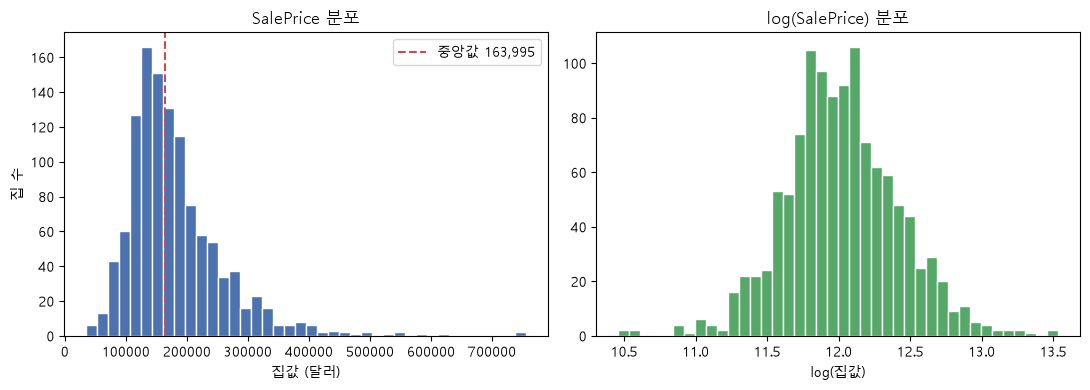

In [114]:
# 집값 분포

import matplotlib.pyplot as plt

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False  # 음수 기호(-)가 깨지는 것 방지

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(train_df['SalePrice'], bins=40, color='#4C72B0', edgecolor='white')
axes[0].axvline(train_df['SalePrice'].median(), color='#C44E52', ls='--',
                label=f"중앙값 {train_df['SalePrice'].median():,.0f}")
axes[0].set_title('SalePrice 분포')
axes[0].set_xlabel('집값 (달러)')
axes[0].set_ylabel('집 수')
axes[0].legend()

axes[1].hist(np.log1p(train_df['SalePrice']), bins=40, color='#55A868', edgecolor='white')
axes[1].set_title('log(SalePrice) 분포')
axes[1].set_xlabel('log(집값)')

plt.tight_layout()
plt.show()

In [115]:
pd.set_option('display.max_rows', None)

num = train_df.select_dtypes(include='number').drop(columns=['Id'])
corr = num.corr()['SalePrice'].drop('SalePrice').sort_values(ascending=False)

corr_table = pd.DataFrame({
    'corr_with_SalePrice': corr.round(3),
    'abs_corr': corr.abs().round(3),
}).sort_values('abs_corr', ascending=False)

print(f"수치형 피처 {len(corr_table)}개와 SalePrice의 상관계수")
corr_table

수치형 피처 36개와 SalePrice의 상관계수


,corr_with_SalePrice,abs_corr
OverallQual,0.785,0.785
GrLivArea,0.710,0.710
GarageCars,0.633,0.633
GarageArea,0.618,0.618
1stFlrSF,0.598,0.598
TotalBsmtSF,0.596,0.596
FullBath,0.578,0.578
TotRmsAbvGrd,0.549,0.549
YearRemodAdd,0.505,0.505
YearBuilt,0.502,0.502


In [116]:
pd.set_option('display.max_rows', None)

y = train_df['SalePrice']
ss_tot = ((y - y.mean()) ** 2).sum()

cat_cols = train_df.select_dtypes(include=['object', 'str']).columns
rows = []
for c in cat_cols:
    g = train_df.groupby(c)['SalePrice']
    ss_between = (g.count() * (g.mean() - y.mean()) ** 2).sum()
    rows.append({
        'feature': c,
        'n_categories': train_df[c].nunique(),
        'eta2': round(ss_between / ss_tot, 3),
        'median_max': round(g.median().max()),
        'median_min': round(g.median().min()),
    })

cat_effect = pd.DataFrame(rows).sort_values('eta2', ascending=False)
print(f"범주형 피처 {len(cat_effect)}개의 집값 차이 (eta2 높은 순)")
cat_effect

범주형 피처 43개의 집값 차이 (eta2 높은 순)


,feature,n_categories,eta2,median_max,median_min
8,Neighborhood,25,0.529,306000,88500
18,ExterQual,4,0.478,341250,81000
30,KitchenQual,4,0.466,313000,115000
21,BsmtQual,4,0.418,314813,114000
34,GarageFinish,3,0.249,214000,135000
20,Foundation,6,0.245,203000,101800
33,GarageType,6,0.195,223750,108000
27,HeatingQC,5,0.194,194350,87000
24,BsmtFinType1,6,0.180,211000,137450
32,FireplaceQu,5,0.171,306000,129000


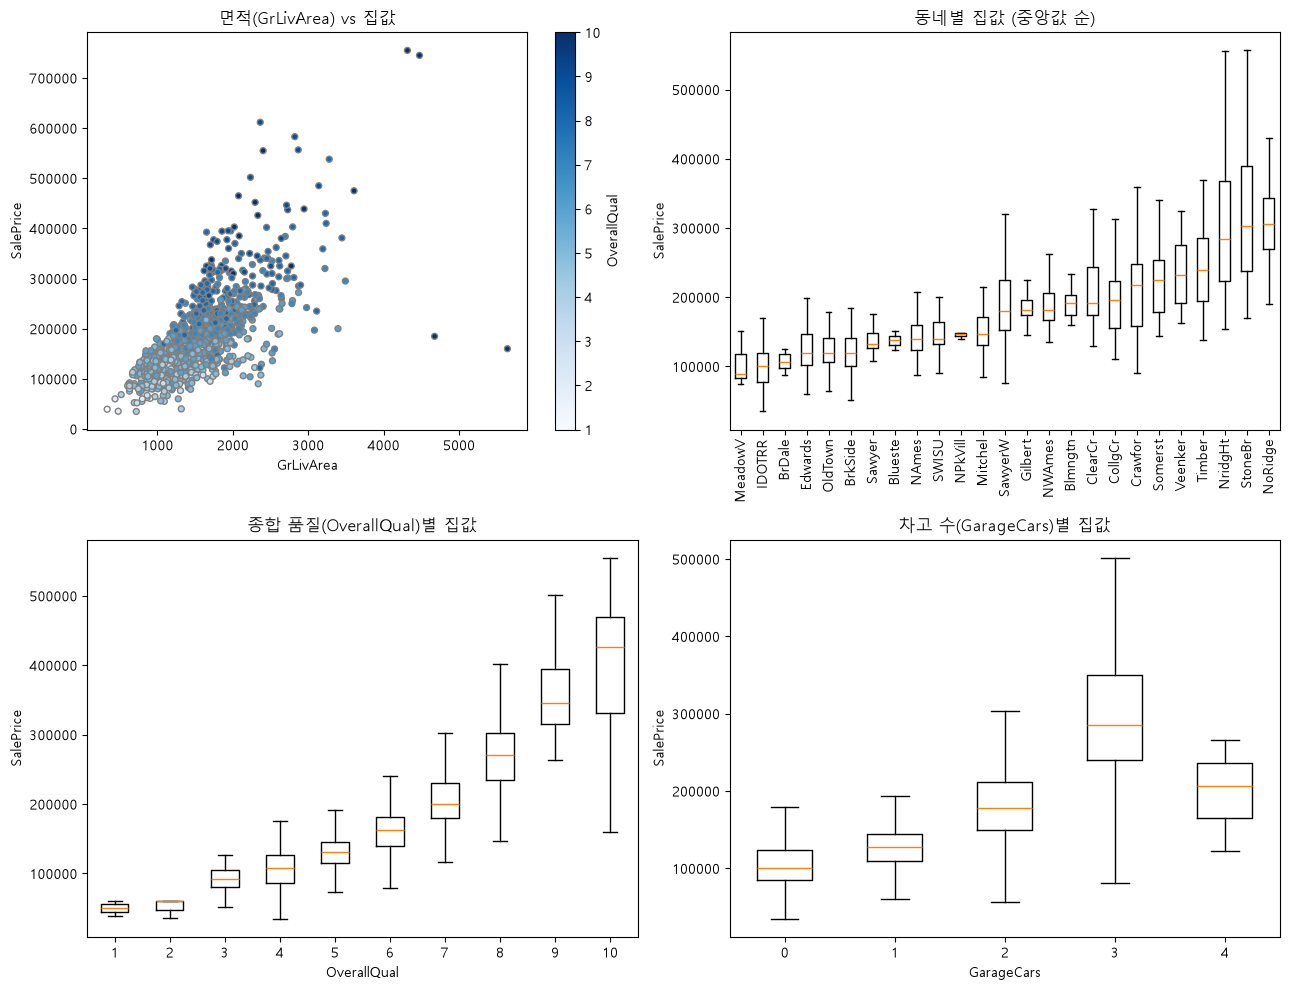

In [117]:
#  예상 주요 피처와 집값의 관계

fig, axes = plt.subplots(2, 2, figsize=(13, 10))

# (1) 면적 vs 집값 (색 = 종합 품질)
ax = axes[0, 0]
sc = ax.scatter(train_df['GrLivArea'], train_df['SalePrice'],
                c=train_df['OverallQual'], cmap='Blues', edgecolor='gray', s=18)
ax.set_title('면적(GrLivArea) vs 집값')
ax.set_xlabel('GrLivArea')
ax.set_ylabel('SalePrice')
fig.colorbar(sc, ax=ax, label='OverallQual')

# (2) 동네별 집값 (중앙값 순)
ax = axes[0, 1]
order = train_df.groupby('Neighborhood')['SalePrice'].median().sort_values().index
ax.boxplot([train_df.loc[train_df['Neighborhood'] == n, 'SalePrice'] for n in order],
           tick_labels=order, showfliers=False)
ax.set_title('동네별 집값 (중앙값 순)')
ax.set_ylabel('SalePrice')
ax.tick_params(axis='x', rotation=90)

# (3) 종합 품질별 집값
ax = axes[1, 0]
q = sorted(train_df['OverallQual'].unique())
ax.boxplot([train_df.loc[train_df['OverallQual'] == v, 'SalePrice'] for v in q],
           tick_labels=q, showfliers=False)
ax.set_title('종합 품질(OverallQual)별 집값')
ax.set_xlabel('OverallQual')
ax.set_ylabel('SalePrice')

# (4) 차고 수별 집값
ax = axes[1, 1]
cars = sorted(train_df['GarageCars'].unique())
ax.boxplot([train_df.loc[train_df['GarageCars'] == v, 'SalePrice'] for v in cars],
           tick_labels=cars, showfliers=False)
ax.set_title('차고 수(GarageCars)별 집값')
ax.set_xlabel('GarageCars')
ax.set_ylabel('SalePrice')

plt.tight_layout()
plt.show()

### 전처리

전처리에서 고민해야 할 것은 많습니다.

1. 이상치
2. 결측치

결측치는 처리하지 않으면 학습 자체가 불가할 수 있기 때문에, 최소한의 전처리로 결측치를 처리하겠습니다.

여러분들이라면 어떻게 결측치를 처리하면 좋을지 고민해보세요!

### 1. 이상치 처리 방향

- 데이터에서 크게 제거할 만한 이상치는 보이지 않습니다.
- 값이 큰 행은 대부분 희귀한 특성(대형 주택, 특수 부대시설, 두 번째 지하실 마감 등)을 가진 매물이라고 판단했습니다.
- 다만 `Id` 1299, 524는 면적과 품질은 최상급인데 가격이 낮고 `Partial`(미완공 판매) 거래입니다. 의심되는 지점이 있지만, 충분히 가능한 거래라고 보고 이 경우에도 **이상치로 제거하지 않습니다.**

In [118]:
pd.set_option('display.max_rows', None)

num = train_df.select_dtypes(include='number').drop(columns=['Id'], errors='ignore')

q1, q3 = num.quantile(0.25), num.quantile(0.75)
iqr = q3 - q1
low, high = q1 - 1.5 * iqr, q3 + 1.5 * iqr
out_mask = (num < low) | (num > high)

outlier_summary = pd.DataFrame({
    'q1': q1, 'q3': q3,
    'lower': low, 'upper': high,
    'outliers': out_mask.sum(),
    'outlier_ratio(%)': (out_mask.mean() * 100).round(2),
    'max': num.max(),
}).query('outliers > 0').sort_values('outliers', ascending=False)

print(f"이상치가 있는 수치형 열: {len(outlier_summary)}개")
outlier_summary.round(2)

이상치가 있는 수치형 열: 31개


,q1,q3,lower,upper,outliers,outlier_ratio(%),max
EnclosedPorch,0.0,0.00,0.00,0.00,169,14.47,552.0
BsmtFinSF2,0.0,0.00,0.00,0.00,127,10.87,1474.0
OverallCond,5.0,6.00,3.50,7.50,106,9.08,9.0
ScreenPorch,0.0,0.00,0.00,0.00,97,8.30,480.0
MSSubClass,20.0,70.00,-55.00,145.00,81,6.93,190.0
MasVnrArea,0.0,168.00,-252.00,420.00,74,6.34,1170.0
LotFrontage,59.0,80.00,27.50,111.50,67,5.74,313.0
OpenPorchSF,0.0,68.00,-102.00,170.00,66,5.65,547.0
BsmtHalfBath,0.0,0.00,0.00,0.00,66,5.65,2.0
KitchenAbvGr,1.0,1.00,1.00,1.00,55,4.71,3.0


### 2.결측치와 처리 방향

In [119]:
# train 데이터셋 결측치 열과 결측치 수
pd.set_option('display.max_rows', None)

na_cols = train_df.isna().sum()
na_cols = na_cols[na_cols > 0].sort_values(ascending=False)

na_info = pd.DataFrame({
    'dtype': train_df[na_cols.index].dtypes,
    'missing_count': na_cols,
    'missing_ratio(%)': (na_cols / len(train_df) * 100).round(2),
})

print(f"결측치가 있는 열: {len(na_info)} / 전체 {train_df.shape[1]}개")
na_info

결측치가 있는 열: 19 / 전체 81개


,dtype,missing_count,missing_ratio(%)
PoolQC,str,1162,99.49
MiscFeature,str,1120,95.89
Alley,str,1098,94.01
Fence,str,941,80.57
MasVnrType,str,694,59.42
FireplaceQu,str,545,46.66
LotFrontage,float64,218,18.66
GarageType,str,69,5.91
GarageYrBlt,float64,69,5.91
GarageFinish,str,69,5.91


### 2.1. 수치형 결측 처리 방향

수치형 결측도 먼저 **결측이 무엇을 뜻하는지** 확인한 뒤 처리합니다. 중앙값으로 일괄 채우면 "차고 없음"이나 "장식 없음"이 실제 값이 있는 것처럼 바뀌기 때문입니다.

#### 1) GarageYrBlt (69개): 차고 없음 → 0
- 결측 69개가 `GarageType` 결측과 완전히 겹칩니다. 차고가 없어서 연도가 없는 것입니다.

#### 2) MasVnrArea (8개): 장식 없음 → 0
- 결측 8개는 `MasVnrType`도 비어 있습니다. 같은 조건의 집 대부분은 면적이 0입니다.

#### 3) LotFrontage (218개): 기록 누락 → 동네별 중앙값
- 결측 집 대부분이 포장도로에 접한 일반 대지이고, 0으로 기록된 값도 없습니다. 0으로 채우면 도로에 닿지 않는 땅이 생기므로 잘못입니다.
- 같은 동네(`Neighborhood`)의 중앙값으로 채웁니다.

In [120]:
pd.set_option('display.max_rows', None)
pd.set_option('display.width', 250)

num_cols = train_df.select_dtypes(include='number').columns
na_num = [c for c in num_cols if train_df[c].isna().any()]

num_summary = pd.DataFrame({
    'missing': train_df[na_num].isna().sum(),
    'missing_ratio(%)': (train_df[na_num].isna().mean() * 100).round(2),
    'n_unique': train_df[na_num].nunique(),
    'min': train_df[na_num].min(),
    'median': train_df[na_num].median(),
    'max': train_df[na_num].max(),
    'zeros': (train_df[na_num] == 0).sum(),
    'sample_values': [list(train_df[c].dropna().unique()[:6]) for c in na_num],
}).sort_values('missing', ascending=False)

print(f'결측이 있는 수치형 열: {len(na_num)}개')
num_summary

결측이 있는 수치형 열: 3개


,missing,missing_ratio(%),n_unique,min,median,max,zeros,sample_values
LotFrontage,218,18.66,104,21.0,69.0,313.0,0,"[60.0, 54.0, 93.0, 44.0, 50.0, 65.0]"
GarageYrBlt,69,5.91,95,1908.0,1980.0,2010.0,0,"[1955.0, 1987.0, 2007.0, 2003.0, 1976.0, 1950.0]"
MasVnrArea,8,0.68,285,0.0,0.0,1170.0,683,"[151.0, 0.0, 72.0, 254.0, 100.0, 292.0]"


In [121]:
# 1) GarageYrBlt: 차고 없음 → 0
train_df['GarageYrBlt'] = train_df['GarageYrBlt'].fillna(0)

# 2) MasVnrArea: 벽돌 장식 없음 → 0
train_df['MasVnrArea'] = train_df['MasVnrArea'].fillna(0)

# 3) LotFrontage: 기록 누락 → 동네별 중앙값 (동네 전체가 결측이면 전체 중앙값)
train_df['LotFrontage'] = train_df.groupby('Neighborhood')['LotFrontage'].transform(
    lambda s: s.fillna(s.median())
)
train_df['LotFrontage'] = train_df['LotFrontage'].fillna(train_df['LotFrontage'].median())

### 2.2. 범주형 결측 처리 방향

범주형 결측 대부분은 "없음"을 뜻하므로 `None`으로 처리합니다. 다만 열의 성격에 따라 두 가지 방식으로 나눕니다.

#### 1) 순서가 있는 열 (품질, 노출, 마감처럼 좋고 나쁨이 있는 것)
- `None`을 0으로 두고 숫자로 바꿉니다.
- 예: `Ex=5, Gd=4, TA=3, Fa=2, Po=1, None=0`

#### 2) 순서가 없는 열 (`Neighborhood`, `RoofStyle` 등)
- `None`을 별도 범주로 두고 원-핫 인코딩합니다.

In [122]:
# 범주형 데이터 종류 확인
pd.set_option('display.max_rows', None)
pd.set_option('display.max_colwidth', 120)

cat_cols = train_df.select_dtypes(include=['object', 'str']).columns

cat_summary = pd.DataFrame({
    'n_unique': train_df[cat_cols].nunique(),
    'missing': train_df[cat_cols].isna().sum(),
    'categories': [
        list(train_df[c].value_counts(dropna=False).index.map(
            lambda x: 'NaN' if pd.isna(x) else x))
        for c in cat_cols
    ],
})

print(f'범주형 열: {len(cat_cols)}개')
cat_summary

범주형 열: 43개


,n_unique,missing,categories
MSZoning,5,0,"[RL, RM, FV, RH, C (all)]"
Street,2,0,"[Pave, Grvl]"
Alley,2,1098,"[NaN, Grvl, Pave]"
LotShape,4,0,"[Reg, IR1, IR2, IR3]"
LandContour,4,0,"[Lvl, Bnk, HLS, Low]"
Utilities,2,0,"[AllPub, NoSeWa]"
LotConfig,5,0,"[Inside, Corner, CulDSac, FR2, FR3]"
LandSlope,3,0,"[Gtl, Mod, Sev]"
Neighborhood,25,0,"[NAmes, CollgCr, OldTown, Edwards, Somerst, Gilbert, Sawyer, NridgHt, NWAmes, SawyerW, BrkSide, Crawfor, Mitchel, ID..."
Condition1,9,0,"[Norm, Feedr, Artery, RRAn, PosN, RRAe, PosA, RRNn, RRNe]"


In [123]:
# 범주형 데이터 결측치 처리 및 인코딩
cat_cols = list(train_df.select_dtypes(include=['object', 'str']).columns)

qual = {'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, 'None': 0}
bsmt_fin = {'GLQ': 6, 'ALQ': 5, 'BLQ': 4, 'Rec': 3, 'LwQ': 2, 'Unf': 1, 'None': 0}
ordinal_maps = {
    'ExterQual': qual, 'ExterCond': qual, 'HeatingQC': qual, 'KitchenQual': qual,
    'BsmtQual': qual, 'BsmtCond': qual, 'FireplaceQu': qual, 'GarageQual': qual,
    'GarageCond': qual, 'PoolQC': qual,
    'BsmtExposure': {'Gd': 4, 'Av': 3, 'Mn': 2, 'No': 1, 'None': 0},
    'BsmtFinType1': bsmt_fin, 'BsmtFinType2': bsmt_fin,
    'GarageFinish': {'Fin': 3, 'RFn': 2, 'Unf': 1, 'None': 0},
    'PavedDrive': {'Y': 2, 'P': 1, 'N': 0},
    'CentralAir': {'Y': 1, 'N': 0},
}

# 1) 실제 결측(Electrical 1개)은 최빈값, 나머지 범주형 결측은 'None'
train_df['Electrical'] = train_df['Electrical'].fillna(train_df['Electrical'].mode()[0])
train_df[cat_cols] = train_df[cat_cols].fillna('None')

# 2) 순서형 → 숫자
for col, m in ordinal_maps.items():
    train_df[col] = train_df[col].map(m)

# 3) 나머지 명목형 → 원-핫
nominal = [c for c in cat_cols if c not in ordinal_maps]
train_df = pd.get_dummies(train_df, columns=nominal, dtype=int)

### 2.3. 최종 결측 및 이상치 제거 확인

앞에서 정한 방향대로 처리한 뒤 결측이 남아 있는지 확인합니다.

- **범주형**: 결측 대부분은 `None`으로 채웠습니다. 순서가 있는 열(품질, 노출, 마감 등)은 `None=0`을 포함해 숫자로 바꾸었고, 순서가 없는 열은 원-핫 인코딩했습니다. `Electrical`의 실제 결측 1개는 최빈값(`SBrkr`)으로 채웠습니다.
- **수치형**: `GarageYrBlt`와 `MasVnrArea`는 0으로, `LotFrontage`는 동네별 중앙값으로 채웠습니다.
- **결과**: `train.csv` 기준으로 전체 결측이 0개가 되었습니다. 원-핫 인코딩 후 열은 240개입니다.
- **이상치**: 아직 제거하지 않았습니다. `GrLivArea`, `LotArea` 같은 면적 열의 극단값은 다음 단계에서 확인합니다.

In [124]:
# 최종 결측 및 이상치 제거 확인
train_df.isna().sum().sum()

np.int64(0)

### 모델 설정 및 학습

In [125]:
from sklearn.model_selection import train_test_split

X = train_df.drop("SalePrice", axis=1)
y = train_df["SalePrice"]

X_train, X_val, y_train, y_val = train_test_split(X, y, test_size=0.2, random_state=42)

In [126]:
print('X_train shape:', X_train.shape)
print('문자열 열:', X_train.select_dtypes(include=['object', 'str']).columns.tolist())
print('결측 개수:', X_train.isna().sum().sum())
print('NaN/inf 있는 열:', X_train.columns[~X_train.apply(lambda s: s.isna().any() or s.isin([float('inf'), float('-inf')]).any())].shape)

X_train shape: (934, 239)
문자열 열: []
결측 개수: 0
NaN/inf 있는 열: (239,)


In [127]:


from sklearn.linear_model import LinearRegression

lr = LinearRegression()
lr.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](239,)","[ 0.06, -173.59, 50.81,..., -3912.24, 10714.24,-19017.06]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](239,)","['Id','MSSubClass','LotFrontage',...,'SaleCondition_Family', 'SaleCondition_Normal','SaleCondition_Partial']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,-4.228e+05
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,239
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(202)


In [128]:
from sklearn.metrics import mean_squared_error
import numpy as np

y_pred = lr.predict(X_val)
rmse = np.sqrt(mean_squared_error(y_val, y_pred))
print("Validation RMSE:", rmse)

Validation RMSE: 31278.827326843897


### 테스트 데이터 예측 및 제출

In [129]:
# 학습 데이터와 동일한 전처리 (결측치 → 순서형 매핑 → 원-핫 인코딩)
test_df = test_df.copy()

# 1) 결측치: 학습 때와 같은 규칙
test_df['GarageYrBlt'] = test_df['GarageYrBlt'].fillna(0)
test_df['MasVnrArea'] = test_df['MasVnrArea'].fillna(0)
test_df['LotFrontage'] = test_df.groupby('Neighborhood')['LotFrontage'].transform(
    lambda s: s.fillna(s.median())
)
test_df['LotFrontage'] = test_df['LotFrontage'].fillna(test_df['LotFrontage'].median())
test_df['Electrical'] = test_df['Electrical'].fillna(test_df['Electrical'].mode()[0])

test_cat_cols = list(test_df.select_dtypes(include=['object', 'str']).columns)
test_df[test_cat_cols] = test_df[test_cat_cols].fillna('None')

# 2) 순서형 → 숫자 (학습 때와 같은 매핑)
qual = {'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, 'None': 0}
bsmt_fin = {'GLQ': 6, 'ALQ': 5, 'BLQ': 4, 'Rec': 3, 'LwQ': 2, 'Unf': 1, 'None': 0}
ordinal_maps = {
    'ExterQual': qual, 'ExterCond': qual, 'HeatingQC': qual, 'KitchenQual': qual,
    'BsmtQual': qual, 'BsmtCond': qual, 'FireplaceQu': qual, 'GarageQual': qual,
    'GarageCond': qual, 'PoolQC': qual,
    'BsmtExposure': {'Gd': 4, 'Av': 3, 'Mn': 2, 'No': 1, 'None': 0},
    'BsmtFinType1': bsmt_fin, 'BsmtFinType2': bsmt_fin,
    'GarageFinish': {'Fin': 3, 'RFn': 2, 'Unf': 1, 'None': 0},
    'PavedDrive': {'Y': 2, 'P': 1, 'N': 0},
    'CentralAir': {'Y': 1, 'N': 0},
}
for col, m in ordinal_maps.items():
    test_df[col] = test_df[col].map(m)

# 3) 나머지 명목형 → 원-핫 (drop_first 없이, 학습과 동일하게)
nominal = [c for c in test_cat_cols if c not in ordinal_maps]
test_df = pd.get_dummies(test_df, columns=nominal, dtype=int)

# 4) 남은 수치형 결측치는 테스트 중앙값으로 채움
test_df = test_df.fillna(test_df.median(numeric_only=True))

# 5) train/test 컬럼 맞추기 (테스트에 없는 컬럼은 0)
test_df = test_df.reindex(columns=X.columns, fill_value=0)

# 예측
test_pred = lr.predict(test_df)

In [130]:
submission = pd.DataFrame({
    "Id": test_df["Id"],
    "SalePrice": test_pred
})
submission.to_csv("submission.csv", index=False)

## 모델 선택 · 규제 · 앙상블

- 1번 셀: 데이터 준비 (먼저 실행)
- 2번 셀: Ridge / Lasso / Decision Tree / Random Forest, 원래 가격 vs log 가격 비교
- 3번 셀: 트리 1개 + 선형 1개 평균 앙상블

In [131]:
# 1. 데이터 준비 (이 셀만 먼저 실행하면 됨)
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold, cross_val_predict, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV, LassoCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

train_df_raw = pd.read_csv('./train.csv')
test_df_raw = pd.read_csv('./test.csv')

def make_features(tr_raw, te_raw):
    df = pd.concat([tr_raw.drop(columns='SalePrice'), te_raw], ignore_index=True)

    # 결측치
    df['GarageYrBlt'] = df['GarageYrBlt'].fillna(0)
    df['MasVnrArea'] = df['MasVnrArea'].fillna(0)
    df['LotFrontage'] = df.groupby('Neighborhood')['LotFrontage'].transform(lambda s: s.fillna(s.median()))
    df['LotFrontage'] = df['LotFrontage'].fillna(df['LotFrontage'].median())
    df['Electrical'] = df['Electrical'].fillna(df['Electrical'].mode()[0])
    cat_cols = list(df.select_dtypes(include=['object', 'str']).columns)
    df[cat_cols] = df[cat_cols].fillna('None')

    # 순서형 → 숫자
    qual = {'Ex': 5, 'Gd': 4, 'TA': 3, 'Fa': 2, 'Po': 1, 'None': 0}
    bsmt_fin = {'GLQ': 6, 'ALQ': 5, 'BLQ': 4, 'Rec': 3, 'LwQ': 2, 'Unf': 1, 'None': 0}
    ordinal_maps = {
        'ExterQual': qual, 'ExterCond': qual, 'HeatingQC': qual, 'KitchenQual': qual,
        'BsmtQual': qual, 'BsmtCond': qual, 'FireplaceQu': qual, 'GarageQual': qual,
        'GarageCond': qual, 'PoolQC': qual,
        'BsmtExposure': {'Gd': 4, 'Av': 3, 'Mn': 2, 'No': 1, 'None': 0},
        'BsmtFinType1': bsmt_fin, 'BsmtFinType2': bsmt_fin,
        'GarageFinish': {'Fin': 3, 'RFn': 2, 'Unf': 1, 'None': 0},
        'PavedDrive': {'Y': 2, 'P': 1, 'N': 0},
        'CentralAir': {'Y': 1, 'N': 0},
    }
    for col, m in ordinal_maps.items():
        df[col] = df[col].map(m)

    # 명목형 → 원-핫
    nominal = [c for c in cat_cols if c not in ordinal_maps]
    df = pd.get_dummies(df, columns=nominal, dtype=int)
    df = df.fillna(df.median(numeric_only=True))

    n = len(tr_raw)
    X = df.iloc[:n].drop(columns='Id')
    X_test = df.iloc[n:].drop(columns='Id')
    return X, X_test, te_raw['Id'].values

X, X_test, test_ids = make_features(train_df_raw, test_df_raw)
y = train_df_raw['SalePrice']
ylog = np.log1p(y)
kf = KFold(5, shuffle=True, random_state=42)
print('X:', X.shape, '| X_test:', X_test.shape)


X: (1168, 240) | X_test: (292, 240)


In [132]:
# 2. 모델 비교: 원래 가격 vs log 가격 (5-fold CV)
models = {
    'Ridge': make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 40))),
    'Lasso': make_pipeline(StandardScaler(),
                           LassoCV(alphas=np.logspace(-4, 2, 30), cv=5, max_iter=50000, random_state=42)),
    'DecisionTree': GridSearchCV(DecisionTreeRegressor(random_state=42),
                                 {'max_depth': [3, 4, 5, 6, 8, 10, None],
                                  'min_samples_leaf': [1, 3, 5, 10, 20]},
                                 cv=kf, scoring='neg_mean_squared_error'),
    'RandomForest': GridSearchCV(RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
                                 {'max_depth': [8, 12, None], 'min_samples_leaf': [1, 3]},
                                 cv=kf, scoring='neg_mean_squared_error'),
}

def run(model, target):
    t = ylog if target == 'log' else y
    p = cross_val_predict(model, X, t, cv=kf)
    if target == 'log':
        p_usd, p_log = np.expm1(p), p
    else:
        p_usd, p_log = p, np.log1p(np.clip(p, 0, None))
    rmse_usd = np.sqrt(np.mean((p_usd - y) ** 2))
    rmse_log = np.sqrt(np.mean((p_log - ylog) ** 2))
    return rmse_usd, rmse_log, p

results = {}
for target in ['raw', 'log']:
    for name, model in models.items():
        usd, lg, p = run(model, target)
        results[(name, target)] = p
        print(f'{name:14s} target={target:3s}  RMSE($)={usd:>9,.0f}  RMSE(log)={lg:.4f}', flush=True)


Ridge          target=raw  RMSE($)=   33,537  RMSE(log)=0.1523
Lasso          target=raw  RMSE($)=   35,095  RMSE(log)=0.3628
DecisionTree   target=raw  RMSE($)=   40,083  RMSE(log)=0.2055
RandomForest   target=raw  RMSE($)=   32,364  RMSE(log)=0.1541
Ridge          target=log  RMSE($)=   47,613  RMSE(log)=0.1444
Lasso          target=log  RMSE($)=   62,427  RMSE(log)=0.1467
DecisionTree   target=log  RMSE($)=   41,806  RMSE(log)=0.2047
RandomForest   target=log  RMSE($)=   31,852  RMSE(log)=0.1508


In [133]:
# 3. 앙상블: 트리 1개 + 선형 1개 평균 (log 타깃 기준)
tree_name, linear_name = 'RandomForest', 'Ridge'
p_ens = np.expm1((results[(tree_name, 'log')] + results[(linear_name, 'log')]) / 2)
rmse_ens = np.sqrt(np.mean((p_ens - y) ** 2))
rmse_ens_log = np.sqrt(np.mean((np.log1p(p_ens) - ylog) ** 2))
print(f'Ensemble({tree_name}+{linear_name})  RMSE($)={rmse_ens:,.0f}  RMSE(log)={rmse_ens_log:.4f}')
# 4. 전체 학습 데이터로 다시 학습 → 테스트 예측 → 원래 가격으로 환산 → submission.csv 저장
final_models = {tree_name: models[tree_name], linear_name: models[linear_name]}
test_logs = []
for name, m in final_models.items():
    m.fit(X, ylog)
    test_logs.append(m.predict(X_test))
test_pred = np.expm1(np.mean(test_logs, axis=0))   # log → 원래 가격

submission = pd.DataFrame({'Id': test_ids, 'SalePrice': test_pred})
submission.to_csv('submission.csv', index=False)
print(submission['SalePrice'].describe().round(0))


Ensemble(RandomForest+Ridge)  RMSE($)=32,597  RMSE(log)=0.1371
count       292.0
mean     178224.0
std       70285.0
min       68433.0
25%      131432.0
50%      157867.0
75%      210548.0
max      512489.0
Name: SalePrice, dtype: float64


In [134]:
# 전체 학습 데이터로 다시 학습 → 테스트 예측 → 원래 가격으로 환산 → submission.csv 저장
final_models = {tree_name: models[tree_name], linear_name: models[linear_name]}

test_logs = []
for name, m in final_models.items():
    m.fit(X, ylog)
    test_logs.append(m.predict(X_test))

test_pred = np.expm1(np.mean(test_logs, axis=0))   # log → 원래 가격

submission = pd.DataFrame({'Id': test_ids, 'SalePrice': test_pred})
submission.to_csv('submission.csv', index=False)
print(submission['SalePrice'].describe().round(0))

count       292.0
mean     178224.0
std       70285.0
min       68433.0
25%      131432.0
50%      157867.0
75%      210548.0
max      512489.0
Name: SalePrice, dtype: float64


## 다항식 피처 (2~4차, 핵심 수치형만)

전체 240개 피처를 다항식으로 확장하면 열이 수만~수백만 개가 되므로, 집값과 관계가 큰 수치형 8개만 확장합니다.
이 8개는 도메인 지식으로 골랐고, 타깃 값을 보고 고르지 않았습니다.

In [135]:
# 4. 다항식 피처 비교 (차수 1=기본, 2, 3, 4)
from sklearn.preprocessing import PolynomialFeatures

poly_cols = ['OverallQual', 'GrLivArea', 'TotalBsmtSF', 'GarageCars',
             'YearBuilt', 'FullBath', '1stFlrSF', 'LotArea']

def add_poly(X_df, deg):
    if deg == 1:
        return X_df
    pf = PolynomialFeatures(degree=deg, include_bias=False)
    P = pf.fit_transform(X_df[poly_cols])
    P_df = pd.DataFrame(P, columns=[f'poly_{n}' for n in pf.get_feature_names_out(poly_cols)],
                        index=X_df.index)
    return pd.concat([X_df, P_df], axis=1)

poly_results = {}
for deg in [1, 2, 3, 4]:
    Xd = add_poly(X, deg)
    for name, model in [
        ('Ridge', make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 40)))),
        ('Lasso', make_pipeline(StandardScaler(),
                                LassoCV(alphas=np.logspace(-4, 2, 30), cv=5, max_iter=50000, random_state=42))),
    ]:
        p = cross_val_predict(model, Xd, ylog, cv=kf)
        rmse_usd = np.sqrt(np.mean((np.expm1(p) - y) ** 2))
        rmse_log = np.sqrt(np.mean((p - ylog) ** 2))
        poly_results[(name, deg)] = rmse_usd
        print(f'deg={deg}  {name:5s}  features={Xd.shape[1]:5d}  RMSE($)={rmse_usd:,.0f}  RMSE(log)={rmse_log:.4f}', flush=True)


deg=1  Ridge  features=  240  RMSE($)=47,613  RMSE(log)=0.1444
deg=1  Lasso  features=  240  RMSE($)=62,427  RMSE(log)=0.1467
deg=2  Ridge  features=  284  RMSE($)=44,110  RMSE(log)=0.1445
deg=2  Lasso  features=  284  RMSE($)=60,334  RMSE(log)=0.1489
deg=3  Ridge  features=  404  RMSE($)=25,962  RMSE(log)=0.1560
deg=3  Lasso  features=  404  RMSE($)=26,943  RMSE(log)=0.1319
deg=4  Ridge  features=  734  RMSE($)=25,758  RMSE(log)=0.2892
deg=4  Lasso  features=  734  RMSE($)=25,907  RMSE(log)=0.4173


In [136]:
# 8. 최종 비교: train / CV(5-fold) / validation(20%) RMSE로 과적합 확인, 타깃은 log·원래 가격 둘 다
from sklearn.preprocessing import PolynomialFeatures
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import train_test_split, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeCV, LassoCV

fixed_cols = ['OverallQual', 'GrLivArea', 'TotalBsmtSF', 'GarageCars',
              'YearBuilt', 'FullBath', '1stFlrSF', 'LotArea']

def poly_feats(Xdf, deg):
    if deg == 1:
        return Xdf
    pf = PolynomialFeatures(degree=deg, include_bias=False)
    P = pf.fit_transform(Xdf[fixed_cols])
    poly_df = pd.DataFrame(P, index=Xdf.index,
                           columns=[f'poly{deg}_{i}' for i in range(P.shape[1])])
    return pd.concat([Xdf, poly_df], axis=1)

def make(name):
    if name.startswith('Ridge'):
        return make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 40)))
    if name.startswith('Lasso'):
        return make_pipeline(StandardScaler(),
                             LassoCV(alphas=np.logspace(-3, 1, 10), cv=3, max_iter=20000, random_state=42))
    if name == 'DecisionTree':
        return DecisionTreeRegressor(max_depth=6, min_samples_leaf=5, random_state=42)
    if name == 'RandomForest':
        return RandomForestRegressor(n_estimators=100, max_depth=12, min_samples_leaf=2,
                                     random_state=42, n_jobs=-1)

names = ['Ridge_d1', 'Ridge_d2', 'Ridge_d3', 'Lasso_d1', 'Lasso_d2', 'Lasso_d3',
         'DecisionTree', 'RandomForest']

def base_name(n):
    return n.split('_')[0]

def deg_of(n):
    return int(n.split('_d')[1]) if '_d' in n else 1

tr_idx, va_idx = train_test_split(np.arange(len(X)), test_size=0.2, random_state=42)

rows = []
for target in ['log', 'raw']:
    t_all = ylog if target == 'log' else y

    def to_usd(p):
        return np.expm1(p) if target == 'log' else p

    for n in names:
        XX = poly_feats(X, deg_of(n)) if base_name(n) in ('Ridge', 'Lasso') else X

        # 1) train RMSE: 전체 train에 학습 후 train에 예측
        m = make(n).fit(XX, t_all)
        tr_usd = np.sqrt(np.mean((to_usd(m.predict(XX)) - y) ** 2))

        # 2) CV RMSE: 5-fold 교차검증
        p_cv = cross_val_predict(make(n), XX, t_all, cv=kf)
        cv_usd = np.sqrt(np.mean((to_usd(p_cv) - y) ** 2))

        # 3) validation RMSE: 80%로 학습, 20%로 평가
        m2 = make(n).fit(XX.iloc[tr_idx], t_all.iloc[tr_idx])
        va_usd = np.sqrt(np.mean((to_usd(m2.predict(XX.iloc[va_idx])) - y.iloc[va_idx]) ** 2))

        rows.append(dict(타깃=target, 모델=n, train=tr_usd, CV=cv_usd,
                         val=va_usd, gap=cv_usd - tr_usd))
        print(f'{target:3s} {n:13s} train={tr_usd:>9,.0f}  CV={cv_usd:>9,.0f}  val={va_usd:>9,.0f}',
              flush=True)

res = pd.DataFrame(rows)
res.to_csv('model_comparison.csv', index=False)
print('\nCV 기준 상위 5개')
print(res.sort_values('CV').head(5).to_string(index=False))
print('\n과적합 gap(CV - train) 작은 순 상위 5개')
print(res.sort_values('gap').head(5).to_string(index=False))


log Ridge_d1      train=   21,850  CV=   47,613  val=   19,197
log Ridge_d2      train=   17,400  CV=   44,110  val=   20,394
log Ridge_d3      train=   17,980  CV=   25,962  val=   19,612
log Lasso_d1      train=   20,172  CV=   64,790  val=   18,806
log Lasso_d2      train=   19,980  CV=   65,524  val=   19,793
log Lasso_d3      train=   17,492  CV=   27,822  val=   20,390
log DecisionTree  train=   26,421  CV=   42,606  val=   34,634
log RandomForest  train=   13,964  CV=   31,575  val=   24,754
raw Ridge_d1      train=   25,904  CV=   33,537  val=   21,752
raw Ridge_d2      train=   19,664  CV=   34,498  val=   25,629
raw Ridge_d3      train=   20,087  CV=   31,816  val=   22,491


c:\Users\jihun\anaconda3\envs\myenv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.690846e+09, tolerance: 4.176e+08
  model = cd_fast.enet_coordinate_descent_gram(
c:\Users\jihun\anaconda3\envs\myenv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.661860e+09, tolerance: 4.176e+08
  model = cd_fast.enet_coordinate_descent_gram(
c:\Users\jihun\anaconda3\envs\myenv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing

raw Lasso_d1      train=   22,383  CV=   36,041  val=   29,775


c:\Users\jihun\anaconda3\envs\myenv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.943295e+09, tolerance: 4.840e+08
  model = cd_fast.enet_coordinate_descent_gram(
c:\Users\jihun\anaconda3\envs\myenv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 4.237885e+10, tolerance: 4.840e+08
  model = cd_fast.enet_coordinate_descent_gram(
c:\Users\jihun\anaconda3\envs\myenv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing

raw Lasso_d2      train=   19,290  CV=   33,499  val=   26,807


c:\Users\jihun\anaconda3\envs\myenv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.229103e+09, tolerance: 4.840e+08
  model = cd_fast.enet_coordinate_descent_gram(
c:\Users\jihun\anaconda3\envs\myenv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 9.230819e+09, tolerance: 4.840e+08
  model = cd_fast.enet_coordinate_descent_gram(
c:\Users\jihun\anaconda3\envs\myenv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:827: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing

raw Lasso_d3      train=   16,297  CV=  212,374  val=   30,266
raw DecisionTree  train=   26,536  CV=   42,077  val=   35,920


c:\Users\jihun\anaconda3\envs\myenv\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:842: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.560098e+10, tolerance: 6.073e+08
  model = cd_fast.enet_coordinate_descent(


raw RandomForest  train=   14,125  CV=   32,113  val=   24,414

CV 기준 상위 5개
 타깃           모델        train           CV          val          gap
log     Ridge_d3 17979.946974 25962.083920 19612.237046  7982.136947
log     Lasso_d3 17491.796451 27822.243830 20390.353459 10330.447379
log RandomForest 13964.157647 31575.307828 24753.635684 17611.150181
raw     Ridge_d3 20087.398823 31815.664017 22490.697836 11728.265194
raw RandomForest 14124.542857 32112.894417 24413.876838 17988.351560

과적합 gap(CV - train) 작은 순 상위 5개
 타깃       모델        train           CV          val          gap
raw Ridge_d1 25904.015619 33537.045950 21751.898080  7633.030332
log Ridge_d3 17979.946974 25962.083920 19612.237046  7982.136947
log Lasso_d3 17491.796451 27822.243830 20390.353459 10330.447379
raw Ridge_d3 20087.398823 31815.664017 22490.697836 11728.265194
raw Lasso_d1 22383.094470 36040.604432 29774.902788 13657.509962


In [138]:
# 최종: Ridge 3차 다항식 + 이상치 2행 제거 (Id 1299, 524) → 테스트 예측 저장
import numpy as np
import pandas as pd
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.pipeline import make_pipeline

fixed_cols = ['OverallQual', 'GrLivArea', 'TotalBsmtSF', 'GarageCars',
              'YearBuilt', 'FullBath', '1stFlrSF', 'LotArea']

def poly_feats(Xdf, deg=3):
    pf = PolynomialFeatures(degree=deg, include_bias=False)
    P = pf.fit_transform(Xdf[fixed_cols])
    poly_df = pd.DataFrame(P, index=Xdf.index,
                           columns=[f'poly{deg}_{i}' for i in range(P.shape[1])])
    return pd.concat([Xdf, poly_df], axis=1)

# 1) 학습 데이터에서 이상치 2행 제외 (테스트 데이터는 그대로)
drop_mask = train_df_raw['Id'].isin([1299, 524]).values
X_clean = X[~drop_mask]
ylog_clean = ylog[~drop_mask]

# 2) 3차 다항식 피처 + Ridge (log 타깃)
model = make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(-2, 4, 40)))
model.fit(poly_feats(X_clean), ylog_clean)

# 3) 테스트 예측 → 원래 가격으로 환산 → 저장
pred_log = model.predict(poly_feats(X_test))
pred = np.expm1(pred_log)
submission_final = pd.DataFrame({'Id': test_ids, 'SalePrice': pred})
submission_final.to_csv('submission_ridge_poly3_clean.csv', index=False)

print('저장 완료: submission_ridge_poly3_clean.csv', submission_final.shape)
print('제외한 행 수:', int(drop_mask.sum()), '| 선택된 alpha:', round(model[-1].alpha_, 2))
print('NaN:', int(submission_final.isna().sum().sum()),
      '| 음수:', int((submission_final.SalePrice < 0).sum()),
      '| 평균:', round(submission_final.SalePrice.mean()),
      '| 최소:', round(submission_final.SalePrice.min()),
      '| 최대:', round(submission_final.SalePrice.max()))

저장 완료: submission_ridge_poly3_clean.csv (292, 2)
제외한 행 수: 2 | 선택된 alpha: 203.09
NaN: 0 | 음수: 0 | 평균: 180068 | 최소: 40820 | 최대: 661903
